# TranAD+ — Parameter Profiling

Our goals are:

- To verify the theoretical parameter-count formula against the original architecture
- To examine parameter distribution
- To identify potential compression targets


## Parameters' count

For the original TranAD+ architecture we define: $F$ as the number of input features and $H$ as the transformer feed-forward dimension. Given these variables, the total number of trainable parameters $N_p$ is given by


$$\boxed{N_p(F,H)=82F^2+12FH+47F+3H}$$

Some more details:

- The number of attention heads equals $F$ in this implementation
- The sequence window length affects computational cost and activation memory but not the trainable parameter count


In [1]:
from pathlib import Path
from collections import defaultdict
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

root = Path.cwd().resolve()

if (root / "tranad_plus" / "TranADPlus").exists():
    root = root / "tranad_plus"
elif (root.parent / "tranad_plus" / "TranADPlus").exists():
    root = root.parent / "tranad_plus"

assert (root / "TranADPlus" / "src" / "models.py").exists()

sys.path.insert(0, str(root / "TranADPlus"))

from src.models import TranAD

output_dir = root.parent / "notebooks" / "profiling_results"
output_dir.mkdir(parents=True, exist_ok=True)

print("Project:", root.resolve())
print("Output:", output_dir.resolve())
print("PyTorch:", torch.__version__)

Project: /Users/darioliotta/Documents/Physics of Data/AD-Satellite-Telemetry/tranad_plus
Output: /Users/darioliotta/Documents/Physics of Data/AD-Satellite-Telemetry/notebooks/profiling_results
PyTorch: 2.2.2


## Useful functions

Every parameter is counted exactly once. The report distinguishes model components from parameter categories.


In [2]:
def theoretical_parameters(features, hidden):
    return 82 * features**2 + 12 * features * hidden + 47 * features + 3 * hidden


def parameter_category(name):
    if "self_attn" in name or "multihead_attn" in name:
        return "Attention"
    if "linear1." in name or "linear2." in name:
        return "Feed-forward"
    if name.startswith("fcn."):
        return "Output"
    return "Other"


def profile_model(dataset, features, hidden, window):
    model = TranAD(
        n_feats=features,
        window_sz=window,
        batch_sz=64,
        dim_feedforward=hidden,
        num_encoder_layers=1,
        num_decoder_layers=1,
    )

    components = defaultdict(int)
    categories = defaultdict(int)

    for name, parameter in model.named_parameters():
        count = parameter.numel()
        components[name.split(".")[0]] += count
        categories[parameter_category(name)] += count

    actual = sum(parameter.numel() for parameter in model.parameters())
    expected = theoretical_parameters(features, hidden)

    assert actual == expected
    assert sum(components.values()) == actual
    assert sum(categories.values()) == actual

    return {
        "Dataset": dataset,
        "F": features,
        "H": hidden,
        "Window": window,
        "Actual": actual,
        "Theoretical": expected,
        "FP32_KiB": actual * 4 / 1024,
        **{f"Component: {k}": v for k, v in components.items()},
        **{f"Category: {k}": v for k, v in categories.items()},
    }


## Experimental configurations


In [10]:
profiles = [
    ("OPS-SAT", 3, 8, 20),
    ("OPS-SAT", 3, 16, 20),
    ("OPS-SAT", 3, 32, 20),
    ("OPS-SAT", 3, 64, 20),
    ("SMAP", 25, 50, 10),
    ("SMD", 38, 16, 20),
]

df = pd.DataFrame([
    profile_model(dataset, features, hidden, window)
    for dataset, features, hidden, window in profiles
]).fillna(0)

df["FP32 (KiB)"] = df["Actual"] * 4 / 1024
df["FP16 (KiB)"] = df["Actual"] * 2 / 1024
df["INT8 (KiB)"] = df["Actual"] / 1024

table = df[
    ["Dataset", "F", "H", "Theoretical", "Actual",
     "FP32 (KiB)", "FP16 (KiB)", "INT8 (KiB)"]
].copy()

display(table.style.format({
    "Theoretical": "{:,.0f}",
    "Actual": "{:,.0f}",
    "FP32 (KiB)": "{:.2f}",
    "FP16 (KiB)": "{:.2f}",
    "INT8 (KiB)": "{:.2f}",
}))

if (table["Theoretical"] == table["Actual"]).all():
    print("Formula seems correct: all theoretical counts coincide with the actual ones.")
else:
    print("Warning: there are some differences between theoretical and actual counts.")
    display(table.loc[table["Theoretical"] != table["Actual"]])

table.to_csv(output_dir / "parameter_report.csv", index=False)

,Dataset,F,H,Theoretical,Actual,FP32 (KiB),FP16 (KiB),INT8 (KiB)
0,OPS-SAT,3,8,"1,191","1,191",4.65,2.33,1.16
1,OPS-SAT,3,16,"1,503","1,503",5.87,2.94,1.47
2,OPS-SAT,3,32,"2,127","2,127",8.31,4.15,2.08
3,OPS-SAT,3,64,"3,375","3,375",13.18,6.59,3.30
4,SMAP,25,50,"67,575","67,575",263.96,131.98,65.99
5,SMD,38,16,"127,538","127,538",498.20,249.10,124.55


Formula seems correct: all theoretical counts coincide with the actual ones.


## Parameter distribution


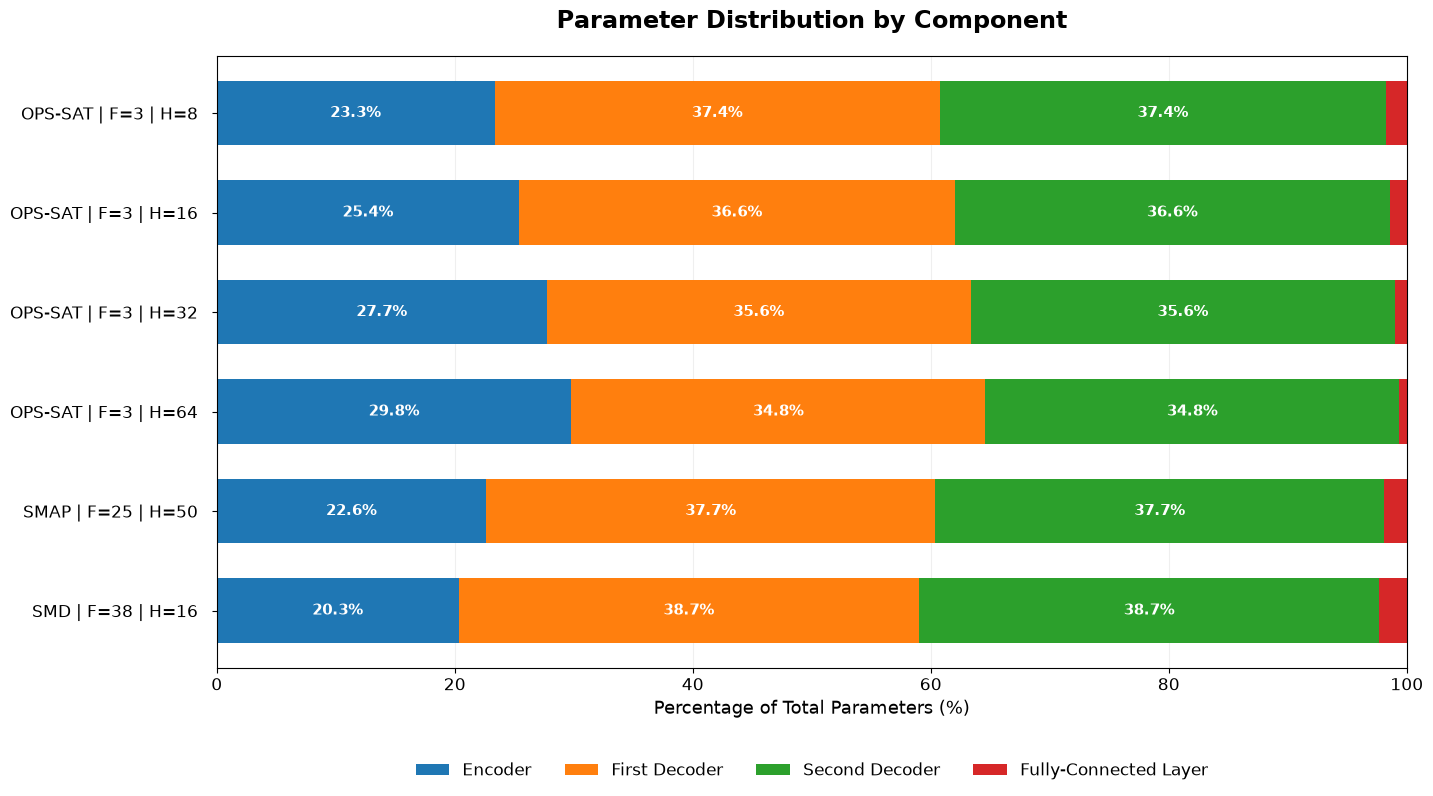

In [21]:
component_columns = [
    col for col in df.columns
    if col.startswith("Component: ")
]

component_data = df.set_index("Profile")[component_columns].copy()

component_data.columns = [
    col.replace("Component: ", "")
    for col in component_columns
]

component_data = component_data.rename(columns={
    "transformer_encoder": "Encoder",
    "transformer_decoder1": "First Decoder",
    "transformer_decoder2": "Second Decoder",
    "fcn": "Fully-Connected Layer"
})

component_data = component_data[
    ["Encoder", "First Decoder", "Second Decoder", "Fully-Connected Layer"]
]

component_percentages = component_data.div(
    component_data.sum(axis=1),
    axis=0
) * 100

fig, ax = plt.subplots(figsize=(17, 9))

component_percentages.plot.barh(
    stacked=True,
    ax=ax,
    width=0.65
)

ax.invert_yaxis()
ax.set_xlim(0, 100)

ax.set_xlabel("Percentage of Total Parameters (%)", fontsize=13)
ax.set_ylabel("")
ax.set_title(
    "Parameter Distribution by Component",
    fontsize=17,
    weight="bold",
    pad=20
)

ax.tick_params(axis="both", labelsize=12)
ax.tick_params(axis="y", pad=10)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() >= 5 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=11,
        color="white",
        weight="bold"
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=4,
    fontsize=12,
    frameon=False
)

fig.subplots_adjust(
    left=0.27,
    right=0.97,
    top=0.90,
    bottom=0.22
)

fig.savefig(
    output_dir / "02_components.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

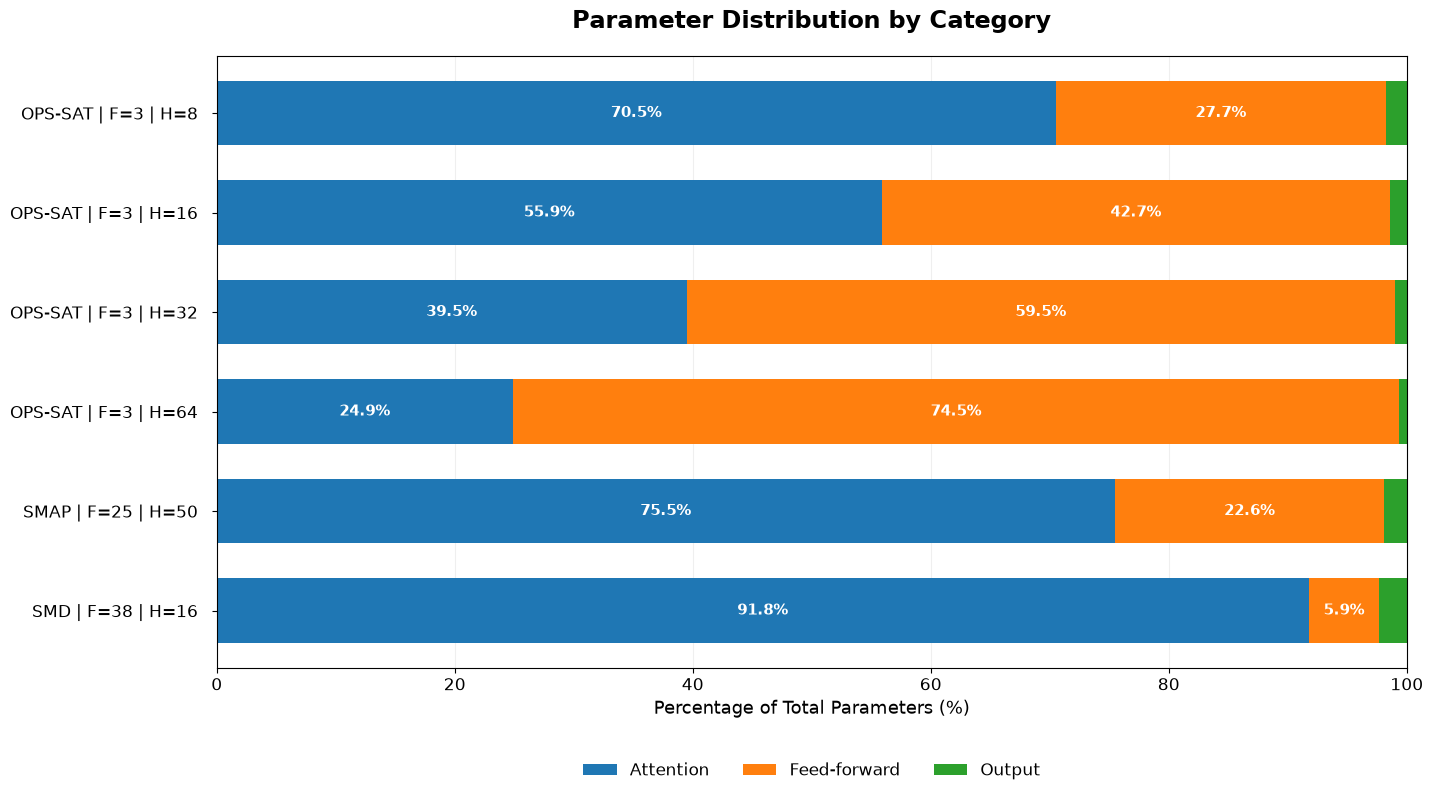

In [22]:
category_columns = [
    col for col in df.columns
    if col.startswith("Category: ")
]

category_data = df.set_index("Profile")[category_columns].copy()

category_data.columns = [
    col.replace("Category: ", "")
    for col in category_columns
]

category_data = category_data.rename(columns={
    "attention": "Attention",
    "feedforward": "Feed-forward",
    "output": "Output",
    "other": "Other"
})

category_data = category_data[
    [
        col for col in ["Attention", "Feed-forward", "Output", "Other"]
        if col in category_data.columns
    ]
]

category_percentages = category_data.div(
    category_data.sum(axis=1),
    axis=0
) * 100

fig, ax = plt.subplots(figsize=(17, 9))

category_percentages.plot.barh(
    stacked=True,
    ax=ax,
    width=0.65
)

ax.invert_yaxis()
ax.set_xlim(0, 100)

ax.set_xlabel("Percentage of Total Parameters (%)", fontsize=13)
ax.set_ylabel("")
ax.set_title(
    "Parameter Distribution by Category",
    fontsize=17,
    weight="bold",
    pad=20
)

ax.tick_params(axis="both", labelsize=12)
ax.tick_params(axis="y", pad=10)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    labels = [
        f"{bar.get_width():.1f}%"
        if bar.get_width() >= 5 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=11,
        color="white",
        weight="bold"
    )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=len(category_data.columns),
    fontsize=12,
    frameon=False
)

fig.subplots_adjust(
    left=0.27,
    right=0.97,
    top=0.90,
    bottom=0.22
)

fig.savefig(
    output_dir / "03_category_percentages.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()